In [22]:
import numpy as np
import matplotlib.pyplot as plt

from quantify_core.data.handling import (
    load_dataset,
    set_datadir,
    default_datadir,
    load_processed_dataset,
)

from quantify_core.analysis import fitting_models as fm

from lmfit import Model

In [23]:
set_datadir(default_datadir())

Data will be saved in:
/home/pschaefers/quantify-data


In [32]:
tuid = "20250926-144608-896-dd7e57"
dataset = load_processed_dataset(tuid, "T1Analysis")

[[Model]]
    Model(t1_decay)
[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 29
    # data points      = 49
    # variables        = 3
    chi-square         = 0.00863159
    reduced chi-square = 1.8764e-04
    Akaike info crit   = -417.563223
    Bayesian info crit = -411.887762
    R-squared          = 0.97882486
[[Variables]]
    A:   0.48819789 +/- 0.01483232 (3.04%) (init = 1)
    T1:  1.0416e-05 +/- 4.7192e-07 (4.53%) (init = 4.8e-05)
    y0: -0.00327258 +/- 0.00258227 (78.91%) (init = 0)
[[Correlations]] (unreported correlations are < 0.100)
    C(A, T1)  = -0.7004
    C(T1, y0) = -0.5197


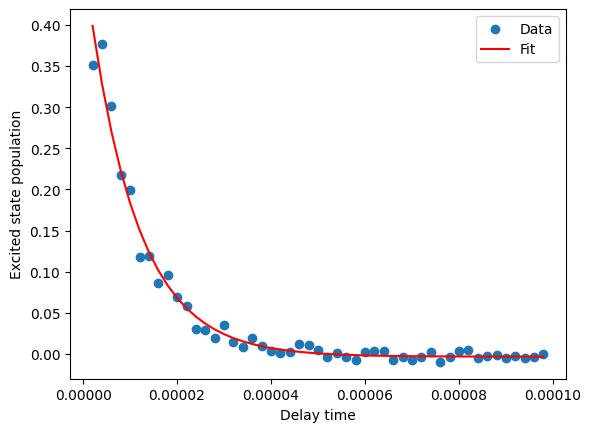

T1 = 10.42 ± 0.47 us


In [39]:
x = dataset.x0.values[1:-1]
y = dataset.pop_exc.values[1:-1]

# T1 decay model
def t1_decay(t, A, T1, y0):
    return A * np.exp(-t / T1) + y0

# Create lmfit model
model = Model(t1_decay)

# Initial guesses
A_guess = 1   # approximate amplitude
T1_guess = (x[-1]-x[0])/2     # rough guess
y0_guess = 0             # final population

params = model.make_params(A=A_guess, T1=T1_guess, y0=y0_guess)

# Fit model
result = model.fit(y, params, t=x)

# Print fit report (includes T1)
print(result.fit_report())

# Plot data and fit
plt.scatter(x, y, label='Data')
plt.plot(x, result.best_fit, label='Fit', color='red')
plt.xlabel('Delay time')
plt.ylabel('Excited state population')
plt.legend()
plt.show()

# Extract T1 value
T1 = result.params['T1'].value*1e6
T1_err = result.params['T1'].stderr*1e6
print(f"T1 = {T1:.2f} ± {T1_err:.2f} us")